# EDA

## Importacions

In [ ]:
import os
import sys

import pandas as pd

sys.path.append(os.path.abspath("../src"))

from constants import RAW_OG_DATA
from tool_scripts.geographic_tools import add_cusec_column

## Cargar los datasets

In [2]:
df_energy_certificates = pd.read_csv(f"{RAW_OG_DATA}/girona_energy_certificates.csv")
df_for_rent_synthetic = pd.read_csv(f"{RAW_OG_DATA}/girona_for_rent_synthetic.csv")
df_for_rent = pd.read_csv(f"{RAW_OG_DATA}/girona_for_rent.csv")
df_services = pd.read_csv(f"{RAW_OG_DATA}/girona_services.csv")
df_sociodemographic = pd.read_csv(f"{RAW_OG_DATA}/girona_sociodemographic.csv")
# df_cedules_habitabilitat = pd.read_csv(f"{ADD_RAW_OG_DATA}/girona_cedules_habitabilitat.csv", low_memory=False)

Reconfiguro la visibilitat dels datasets per veure totes les columnes

In [3]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

## DEMOGRAPHIC DATASET

`census_tract` es la Secció censal INE, la unitat territorial més petita per estudis socioeconomicodemogràfics i es pot calcular gràcies a dades del INE i la latitud i longitud (per a més informació mirar `04_census_tract_generator.ipynb`)

In [17]:
df_for_rent_synthetic_census = add_cusec_column(df_for_rent_synthetic, "lat", "lon")

Gràcies a la funció `crear_mapa()` he pogut veure que hi ha files amb localitzacions fora de Girona ("17079XXXXX"):

In [18]:
df_for_rent_synthetic_census = df_for_rent_synthetic_census[
    df_for_rent_synthetic_census["census_tract"].str.startswith("17079")
]
df_for_rent_synthetic_census

,synthetic_id,year_available,address,price,area,rooms,neighbourhood,floors,elevator,lat,lon,census_tract
0,2015-0001,2015,"Calle de Santiago, 62",1145,62,2,Migdia Casernes,1,False,41.968318,2.816188,1707902011
1,2015-0002,2015,"Calle de Sant Agustí, 42",695,67,2,Migdia Casernes,4,True,41.970975,2.821103,1707902010
2,2015-0003,2015,"Calle Mare de Déu del Remei, 11",755,91,4,Sant Narcís,2,True,41.976793,2.812300,1707903016
3,2015-0004,2015,"Calle Bonastruc de Porta, 67",755,104,3,Devesa,1,False,41.984938,2.819815,1707903003
4,2015-0005,2015,"Calle Jocs Olímpics de Barcelona, 33",1020,86,3,Palau,0,True,41.958326,2.820114,1707902020
...,...,...,...,...,...,...,...,...,...,...,...,...
2492,2023-2493,2023,"Eixample, 5",1735,144,4,NaN,5,True,41.979981,2.819087,1707902003
2494,2023-2495,2023,"Calle Emili Grahit, 23",2520,139,4,Eixample,4,True,41.972988,2.830314,1707902014
2496,2023-2497,2023,"Calle del Riu Güell, 50",2270,204,2,Devesa,3,True,41.985234,2.819595,1707903003
2497,2023-2498,2023,"Barri Vell, 71",1260,110,2,NaN,2,True,41.984231,2.825146,1707904001


In [ ]:
from tool_scripts.geographic_tools import crear_mapa

crear_mapa(
    df_for_rent_synthetic_census, name_html="localitzacio_habitatges_filtrats.html"
)

## ENERGY CERTIFICATES + SOCIODEMOGRAPHIC DATASET ?

In [5]:
print(f"Total registros en energy_certificates: {len(df_energy_certificates)}")
print(f"Total registros en sociodemographic: {len(df_sociodemographic)}")

census_energy = set(df_energy_certificates["census_tract"].unique())
census_socio = set(df_sociodemographic["census_tract"].unique())

print(f"\nTotal únicos en energy_certificates: {len(census_energy)}")
print(f"Total únicos en sociodemographic: {len(census_socio)}")

only_in_energy = census_energy - census_socio
only_in_socio = census_socio - census_energy

print(f"\nCensus_tract solo en energy_certificates: {len(only_in_energy)}")

print(f"\nCensus_tract solo en sociodemographic: {len(only_in_socio)}")

Total registros en energy_certificates: 18235
Total registros en sociodemographic: 552

Total únicos en energy_certificates: 62
Total únicos en sociodemographic: 62

Census_tract solo en energy_certificates: 0

Census_tract solo en sociodemographic: 0


Juntar-los dona com a resultat un dataframe amb una definició de fila molt ambigüa, cada fila seria el certificat energètic d'una casa concreta junt amb dades sociodemogràfiques, que fariem que aqust mateix certificat es veiés en vàries files però diferents anys.

Crec que val la pena que si s'utilitzi un es vagi a buscar la informació a l'altre si escau.

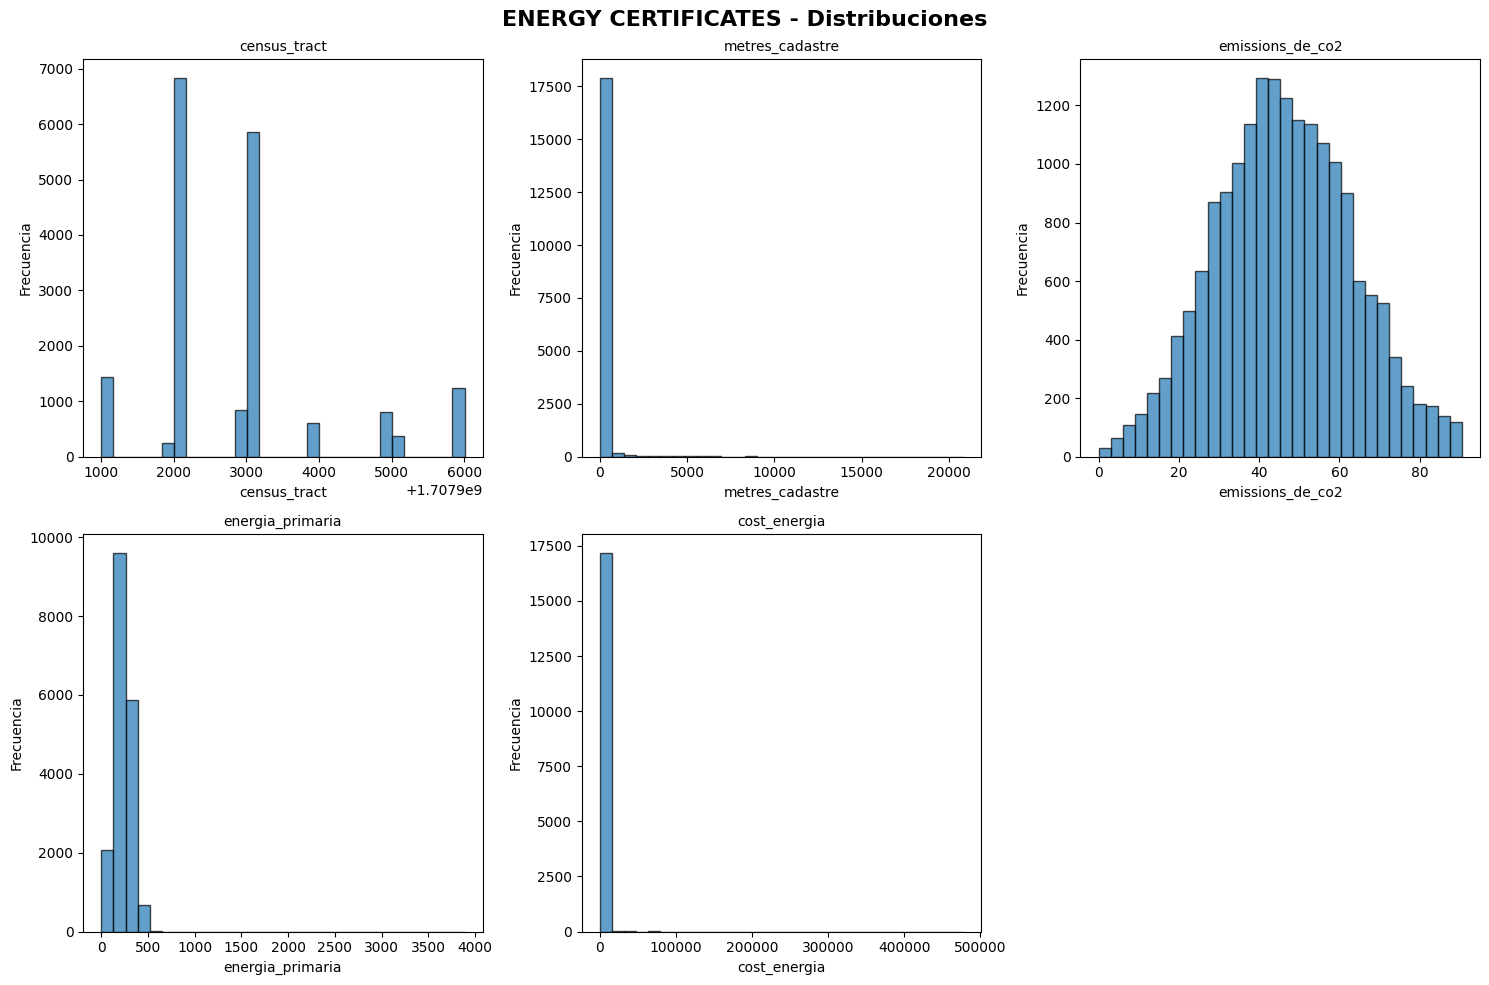

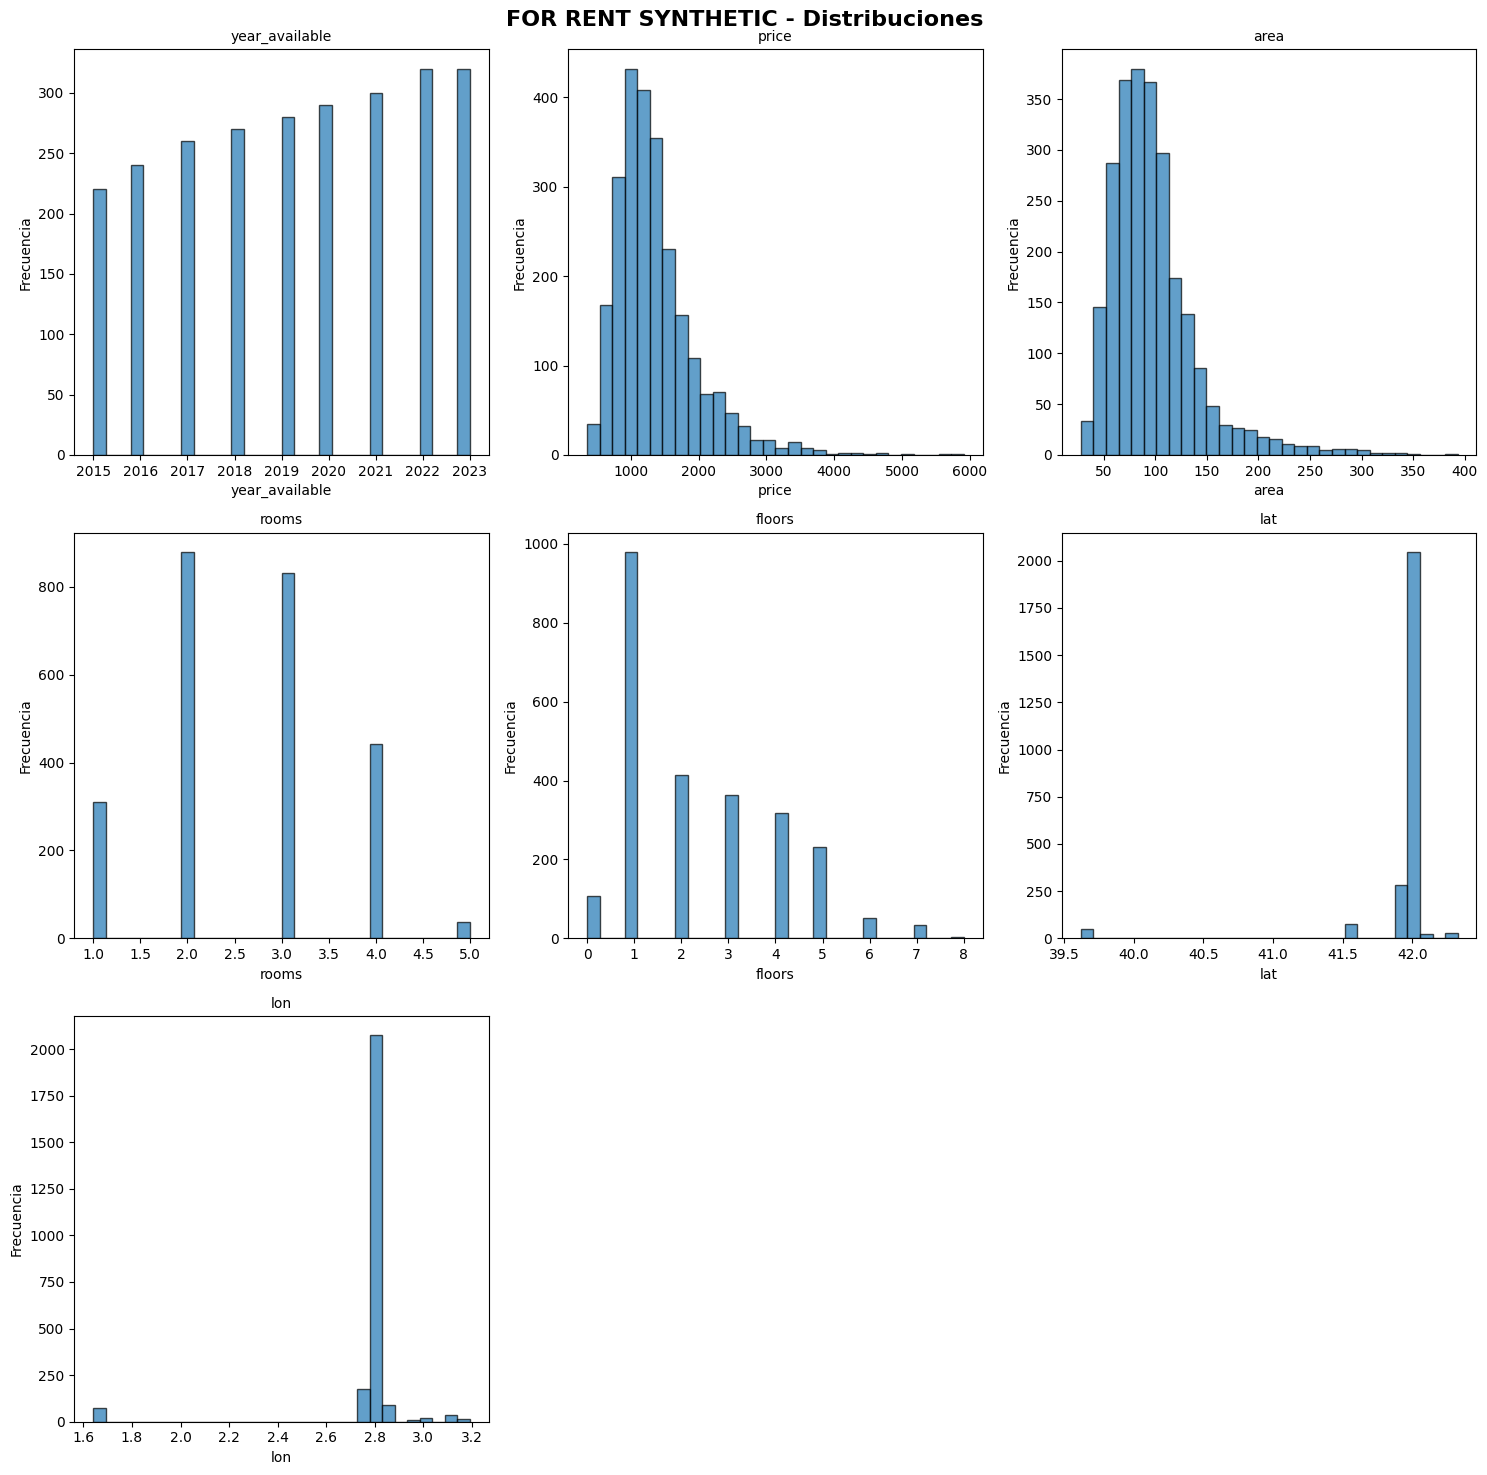

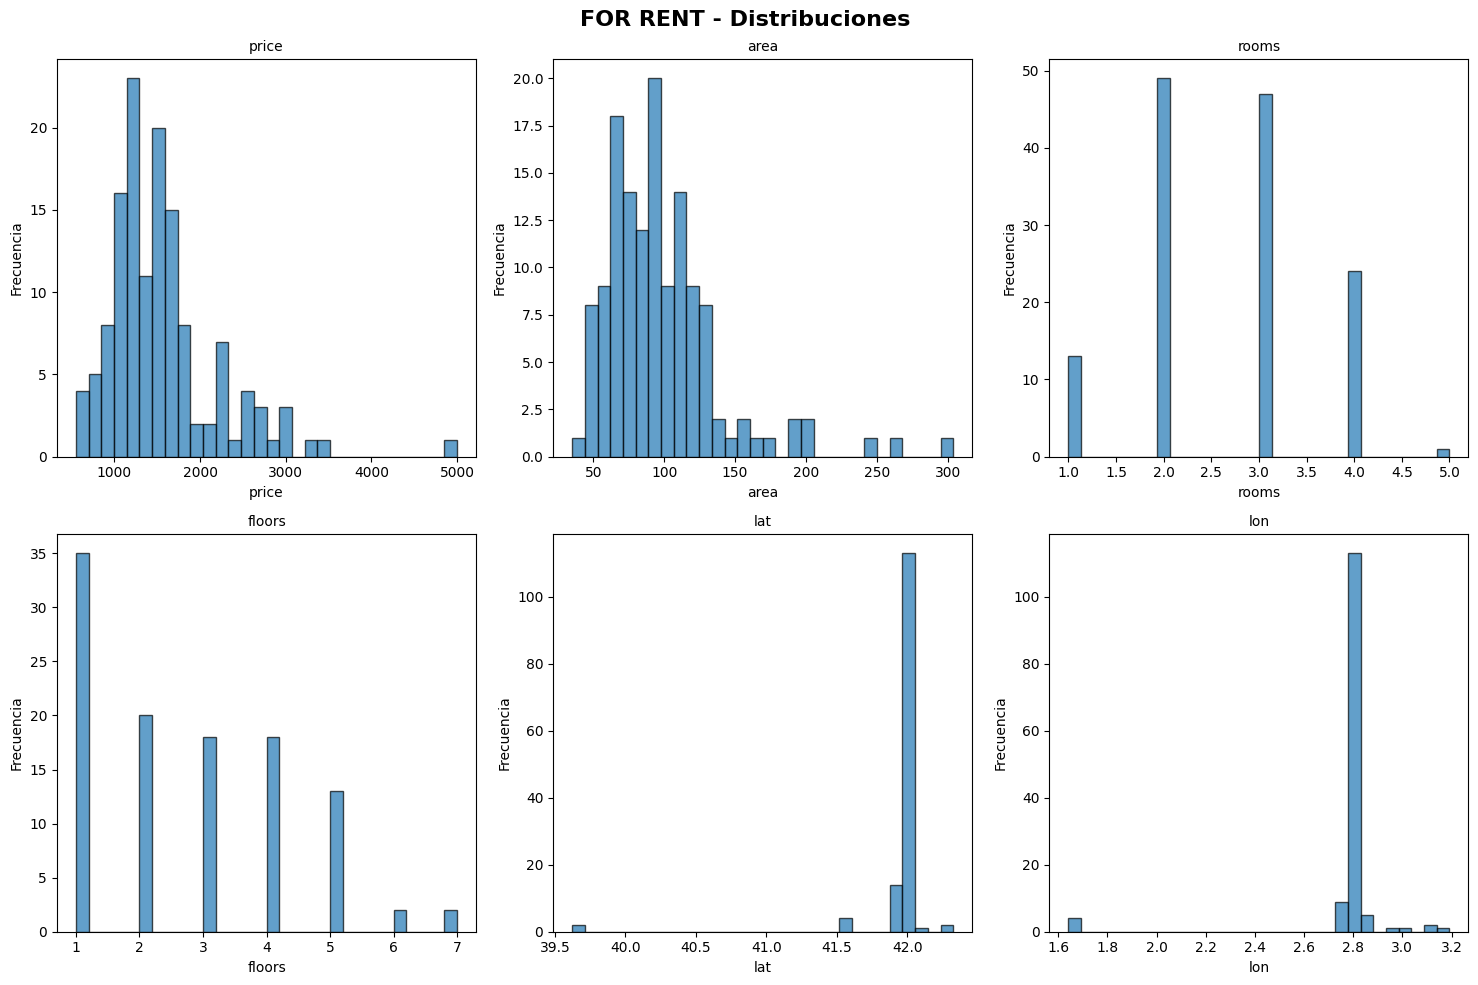

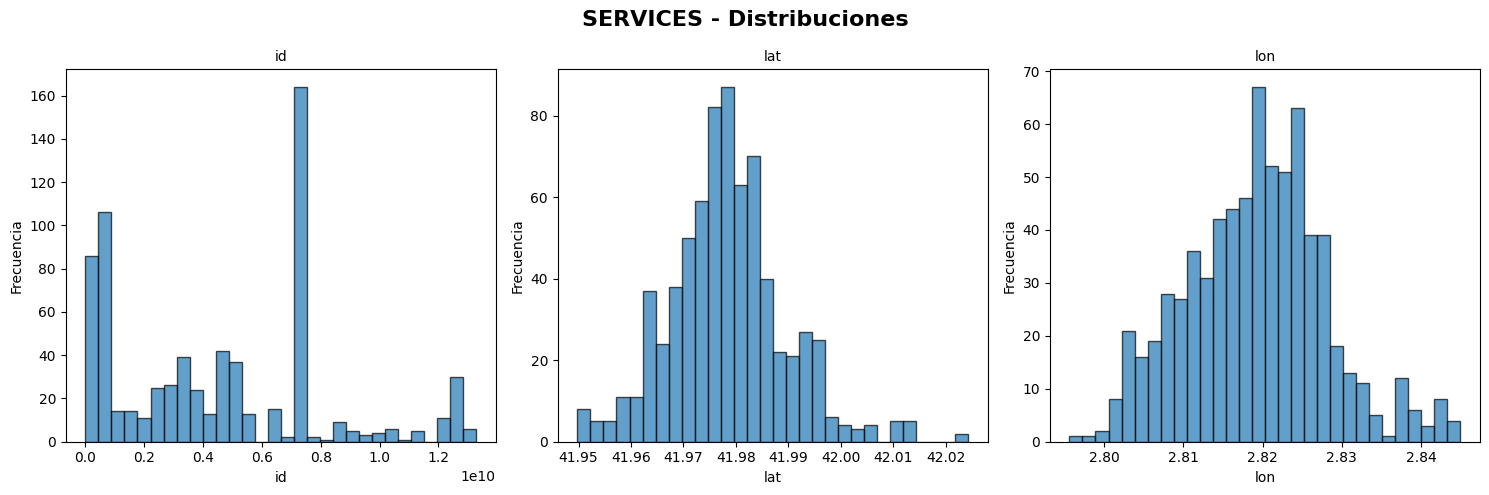

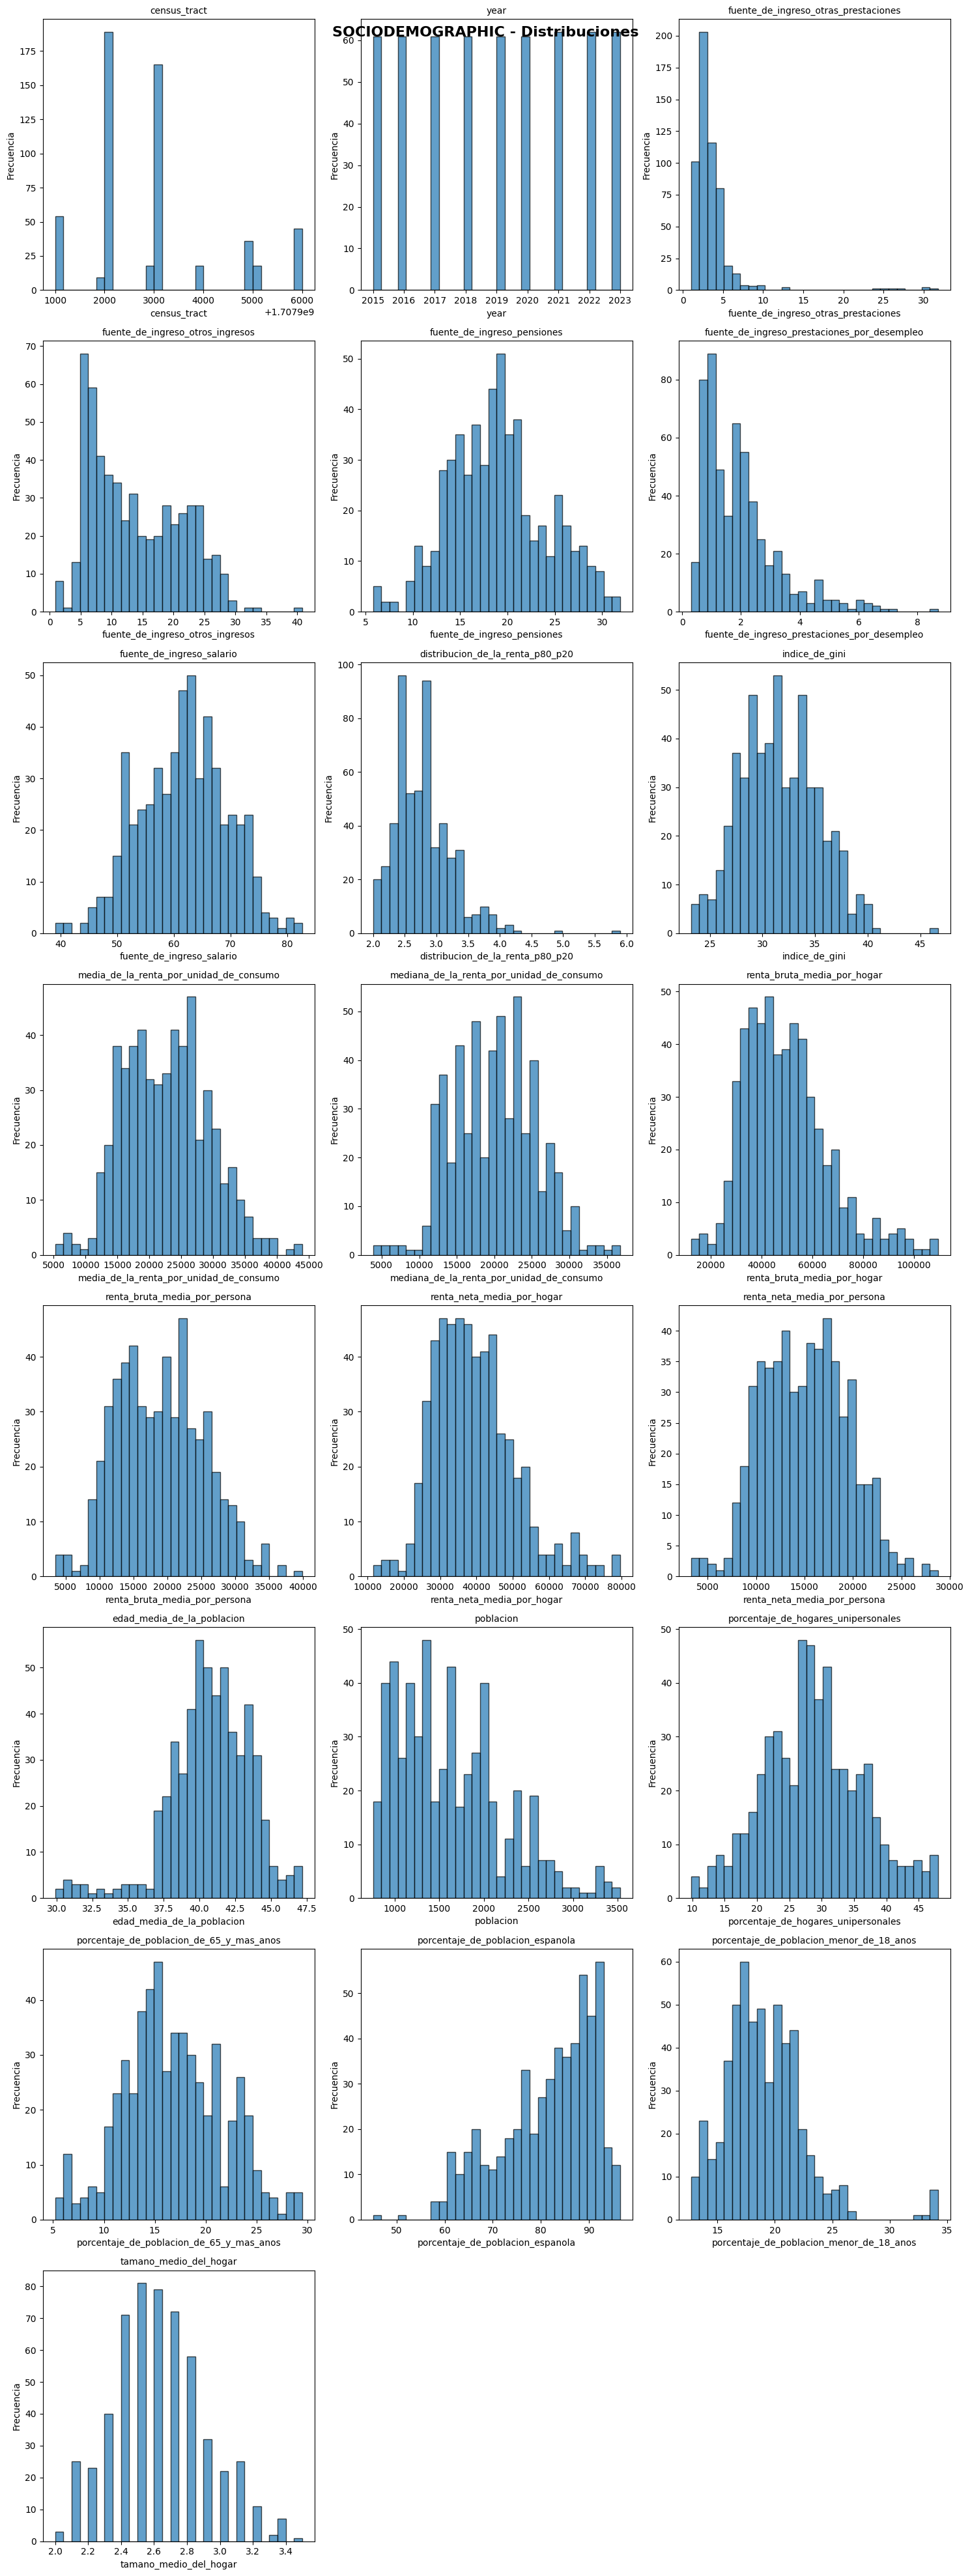

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

dataframes = [
    ("ENERGY CERTIFICATES", df_energy_certificates),
    ("FOR RENT SYNTHETIC", df_for_rent_synthetic),
    ("FOR RENT", df_for_rent),
    ("SERVICES", df_services),
    ("SOCIODEMOGRAPHIC", df_sociodemographic),
]

for df_name, df in dataframes:
    # Seleccionamos solo columnas numéricas
    numeric_cols = df.select_dtypes(include="number").columns

    # Filtrar columnas no vacías
    valid_cols = [col for col in numeric_cols if not df[col].dropna().empty]

    if not valid_cols:
        print(f"No hay columnas numéricas válidas en {df_name}")
        continue

    # Calcular el número de filas y columnas para el grid
    n_cols = 3  # número de columnas en el grid
    n_rows = int(np.ceil(len(valid_cols) / n_cols))

    # Crear figura con subplots
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
    fig.suptitle(f"{df_name} - Distribuciones", fontsize=16, fontweight="bold")

    # Aplanar axes para iterar fácilmente
    axes = axes.flatten() if n_rows > 1 or n_cols > 1 else [axes]

    # Crear histograma para cada columna
    for idx, col in enumerate(valid_cols):
        axes[idx].hist(df[col].dropna(), bins=30, edgecolor="black", alpha=0.7)
        axes[idx].set_title(col, fontsize=10)
        axes[idx].set_xlabel(col)
        axes[idx].set_ylabel("Frecuencia")

    # Ocultar subplots vacíos
    for idx in range(len(valid_cols), len(axes)):
        axes[idx].set_visible(False)

    plt.tight_layout()
    plt.show()